# IMPORTATION DE LIBRAIRIES

📘 1. import tensorflow as tf

TensorFlow est la bibliothèque principale pour construire et entraîner des réseaux de neurones.

On l’importe sous le nom abrégé tf (par convention).

TensorFlow contient tous les outils bas niveau : calcul matriciel, GPU, graphes de calcul, etc.

🧱 2. from tensorflow.keras.models import Sequential

Keras est une interface haut niveau de TensorFlow.

Elle permet de créer des modèles rapidement sans écrire tout le calcul mathématique à la main.

Sequential est une façon simple de construire un modèle :

tu empiles les couches les unes après les autres, comme des blocs LEGO.

👉 Exemple :

model = Sequential()


Ensuite tu ajoutes des couches :

model.add(Conv2D(...))

🧠 3. from tensorflow.keras.layers import ...

Ce module contient tous les types de couches qu’on utilise dans un CNN.

a) Conv2D

C’est la couche de convolution (2D car image = matrice 2D).

Elle apprend les filtres qui détectent les motifs visuels.

👉 Exemple :

Conv2D(32, (3,3), activation='relu', input_shape=(64, 64, 3))

b) MaxPooling2D

C’est la couche de pooling (réduction de taille).

Elle garde la valeur maximale dans chaque zone 2×2 → plus de robustesse et moins de calculs.

c) Flatten

Convertit une matrice (par ex. 8×8×128) en un vecteur 1D.

C’est la transition entre la partie convolutionnelle et la partie dense.

d) Dense

C’est une couche de neurones classiques (fully connected).

Chaque neurone est relié à tous ceux de la couche précédente.

e) Dropout

C’est une couche de régularisation.

Elle “éteint” aléatoirement certains neurones pendant l’entraînement → empêche le surapprentissage (overfitting).

🧾 4. from tensorflow.keras.preprocessing.image import ImageDataGenerator

C’est une classe très pratique pour charger automatiquement les images depuis des dossiers et les prétraiter avant de les donner au réseau.

Elle permet :

de normaliser les pixels (0–1),

de créer des images augmentées (rotations, zooms, flips),

et de gérer automatiquement les classes à partir des noms des dossiers.

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from PIL import Image
import os, random


In [151]:
background_dir = "backgrounds"
backgrounds = [os.path.join(background_dir, f) for f in os.listdir(background_dir)]


In [152]:
def random_background(img, threshold=240):
    bg = Image.open(random.choice(backgrounds)).convert("RGB")
    bg = bg.resize(img.size)

    img_np = np.array(img)
    bg_np = np.array(bg)

    mask = np.all(img_np > threshold, axis=2)
    img_np[mask] = bg_np[mask]

    return Image.fromarray(img_np)


In [153]:
def preprocess_image(img):
    # 40% chance to swap background
    if np.random.rand() < 0.4:
        img = random_background(img)

    img = np.array(img) / 255.0
    return img


In [154]:
class CutMixGenerator(tf.keras.utils.Sequence):
    def __init__(self, generator, batch_size=32):
        self.generator = generator
        self.batch_size = batch_size

    def __len__(self):
        return len(self.generator)

    def __getitem__(self, index):
        x, y = self.generator[index]

        # Skip incomplete batches
        if x.shape[0] < self.batch_size:
            return x, y

        index2 = np.random.randint(0, len(self.generator))
        x2, y2 = self.generator[index2]

        if x2.shape[0] < self.batch_size:
            return x, y

        h, w = x.shape[1], x.shape[2]
        cut_w = np.random.randint(w // 8, w // 2)
        cut_h = np.random.randint(h // 8, h // 2)

        cx = np.random.randint(w)
        cy = np.random.randint(h)

        x1 = np.clip(cx - cut_w // 2, 0, w)
        x2b = np.clip(cx + cut_w // 2, 0, w)
        y1 = np.clip(cy - cut_h // 2, 0, h)
        y2b = np.clip(cy + cut_h // 2, 0, h)

        x[:, y1:y2b, x1:x2b, :] = x2[:, y1:y2b, x1:x2b, :]

        lam = 1 - ((x2b - x1) * (y2b - y1) / (w * h))
        y = lam * y + (1 - lam) * y2

        return x, y


In [155]:
class MixUpGenerator(tf.keras.utils.Sequence):
    def __init__(self, generator, batch_size=32, alpha=0.2):
        self.generator = generator
        self.batch_size = batch_size
        self.alpha = alpha

    def __len__(self):
        return len(self.generator)

    def __getitem__(self, index):
        x, y = self.generator[index]
        if x.shape[0] < self.batch_size:
            return x, y

        lam = np.random.beta(self.alpha, self.alpha)
        index2 = np.random.randint(0, len(self.generator))
        x2, y2 = self.generator[index2]
        if x2.shape[0] < self.batch_size:
            return x, y

        # ✅ Apply random background
        for i in range(x.shape[0]):
            img = Image.fromarray((x[i]*255).astype("uint8"))
            img = preprocess_image(img)
            x[i] = img

        x = lam * x + (1 - lam) * x2
        y = lam * y + (1 - lam) * y2

        return x, y


# 🗂️ 2. Organisation du dossier

In [156]:
img_size = (128, 128)
batch_size = 32

datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,
    rotation_range=20,
    zoom_range=0.2,
    brightness_range=[0.7, 1.3]
)

train_raw = datagen.flow_from_directory(
    "dataset/",
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='training'
)

val_gen = datagen.flow_from_directory(
    "dataset/",
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='validation'
)

train_cutmix = CutMixGenerator(train_raw, batch_size=batch_size)
train_gen = MixUpGenerator(train_cutmix, batch_size=batch_size)


Found 234 images belonging to 16 classes.
Found 50 images belonging to 16 classes.


In [157]:
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(128,128,3)
)
base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.4)(x)

num_classes = train_raw.num_classes
outputs = Dense(num_classes, activation='softmax')(x)

model = Model(base_model.input, outputs)

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
model.summary()


Model: "functional_46"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_10      │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 64, 64,    │        864 │ input_layer_10[0… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 64, 64,    │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 64, 64,    │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 64, 64,    │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 64, 64,    │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 64, 64,    │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 64, 64,    │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 64, 64,    │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 65, 65,    │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 32, 32,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 32, 32,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 32, 32,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 32, 32,    │      2,304 │ block_1_depthwis

 Total params: 2,590,032 (9.88 MB)

 Trainable params: 332,048 (1.27 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [158]:
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2)

history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=20,
    steps_per_epoch=len(train_raw),
    validation_steps=len(val_gen),
    callbacks=[early_stop, reduce_lr]
)


Epoch 1/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 40s 4s/step - accuracy: 0.2308 - loss: 2.7233 - val_accuracy: 0.5800 - val_loss: 1.4181 - learning_rate: 0.0010
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 23s 3s/step - accuracy: 0.5299 - loss: 1.9336 - val_accuracy: 0.7200 - val_loss: 1.0894 - learning_rate: 0.0010
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 26s 3s/step - accuracy: 0.6325 - loss: 1.5089 - val_accuracy: 0.8000 - val_loss: 0.8080 - learning_rate: 0.0010
Epoch 4/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 25s 3s/step - accuracy: 0.6752 - loss: 1.3367 - val_accuracy: 0.7800 - val_loss: 0.7829 - learning_rate: 0.0010
Epoch 5/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 23s 3s/step - accuracy: 0.6325 - loss: 1.4008 - val_accuracy: 0.8200 - val_loss: 0.7250 - learning_rate: 0.0010
Epoch 6/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 22s 3s/step - accuracy: 0.7991 - loss: 0.9715 - val_accuracy: 0.7400 - val_loss: 0.7122 - learning_rate: 0.0010
Epoch 7/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 29s 4s/step - accuracy: 0.7094 - loss: 1.3926 - val_accuracy: 0.8400 - val_l

In [159]:
base_model.trainable = True

for layer in base_model.layers[:100]:  # on garde les premières couches gelées
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_ft = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=10,
    callbacks=[early_stop, reduce_lr]
)


Epoch 1/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 53s 4s/step - accuracy: 0.6538 - loss: 1.2890 - val_accuracy: 0.9000 - val_loss: 0.3108 - learning_rate: 1.0000e-05
Epoch 2/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 28s 3s/step - accuracy: 0.6368 - loss: 1.4823 - val_accuracy: 0.8800 - val_loss: 0.3860 - learning_rate: 1.0000e-05
Epoch 3/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 24s 3s/step - accuracy: 0.7137 - loss: 1.2349 - val_accuracy: 0.8800 - val_loss: 0.3769 - learning_rate: 3.0000e-06
Epoch 4/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 25s 3s/step - accuracy: 0.5812 - loss: 1.7824 - val_accuracy: 0.9200 - val_loss: 0.3310 - learning_rate: 3.0000e-06
Epoch 5/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 27s 3s/step - accuracy: 0.5641 - loss: 1.6143 - val_accuracy: 0.9400 - val_loss: 0.2798 - learning_rate: 9.0000e-07
Epoch 6/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 26s 3s/step - accuracy: 0.5983 - loss: 1.5323 - val_accuracy: 0.9200 - val_loss: 0.3557 - learning_rate: 9.0000e-07
Epoch 7/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 24s 3s/step - accuracy: 0.6709 - loss: 1.3036 - val_

2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 883ms/step


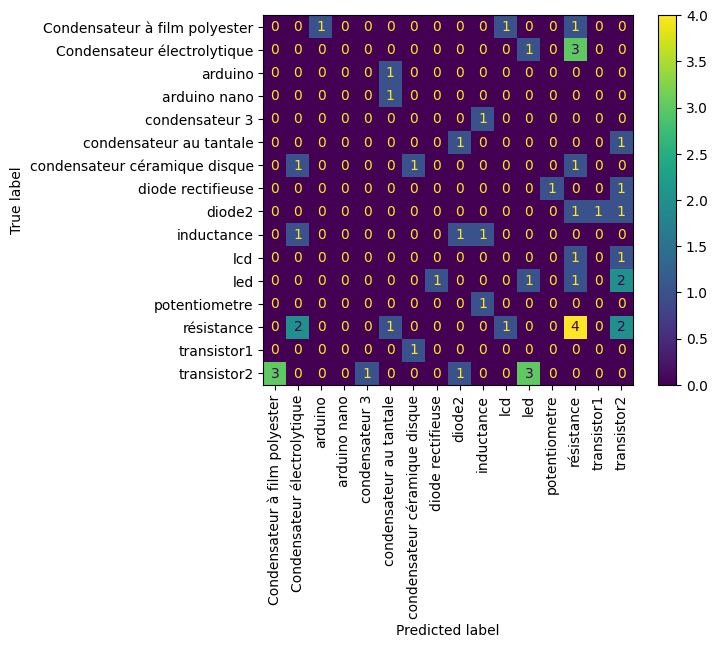

In [161]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Prédictions
y_true = val_gen.classes
y_pred = np.argmax(model.predict(val_gen), axis=1)

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(cm, display_labels=list(train_raw.class_indices.keys()))
disp.plot(xticks_rotation='vertical')
plt.show()


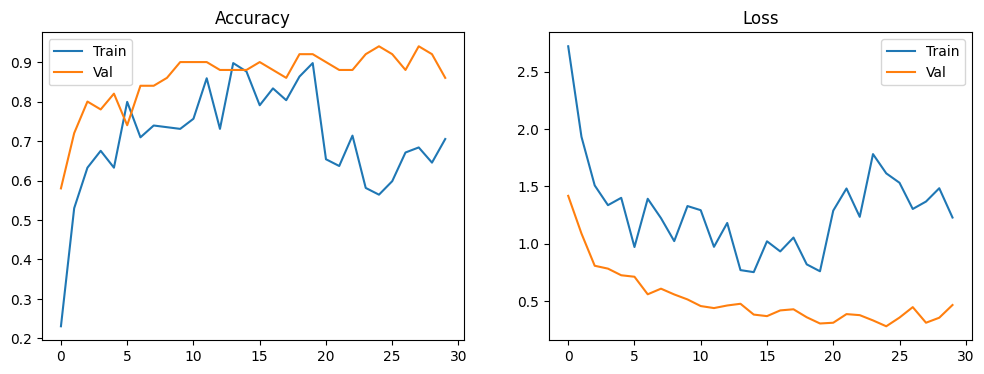

In [162]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'] + history_ft.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'] + history_ft.history['val_accuracy'], label='Val')
plt.title('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'] + history_ft.history['loss'], label='Train')
plt.plot(history.history['val_loss'] + history_ft.history['val_loss'], label='Val')
plt.title('Loss')
plt.legend()

plt.show()


In [163]:
print(f"Final train accuracy: {history.history['accuracy'][-1] * 100:.2f}%")
print(f"Final val accuracy: {history.history['val_accuracy'][-1] * 100:.2f}%")


Final train accuracy: 89.74%
Final val accuracy: 92.00%


In [164]:
model.save("component_classifier.h5")
print("✅ Modèle sauvegardé sous component_classifier.h5")


✅ Modèle sauvegardé sous component_classifier.h5


In [166]:
import json

with open("classes.json", "w") as f:
    json.dump(train_raw.class_indices, f)

print("✅ classes.json sauvegardé !")


✅ classes.json sauvegardé !


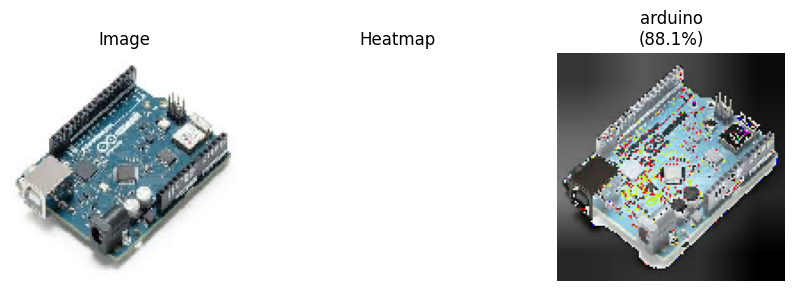


✅ Classe prédite : arduino
🎯 Confiance : 88.13%
📂 Image : C:/Users/PC/Downloads/th.jpg


In [5]:
import tkinter as tk
from tkinter import filedialog
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from PIL import Image
import matplotlib.pyplot as plt
import json

# ==== Charger modèle + classes ====
model = load_model("component_classifier.h5")

with open("classes.json") as f:
    class_indices = json.load(f)
class_names = {v:k for k,v in class_indices.items()}

IMG_SIZE = (128,128)
LAST_CONV_LAYER = "Conv_1"  # Dernière couche conv MobileNetV2

def preprocess_image(path):
    img = load_img(path, target_size=IMG_SIZE)
    img_arr = img_to_array(img) / 255.0
    img_arr = np.expand_dims(img_arr, axis=0)
    return img, img_arr

def grad_cam(img_array):
    grad_model = tf.keras.models.Model(
        [model.inputs],
        [model.get_layer(LAST_CONV_LAYER).output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, preds = grad_model(img_array)
        pred_index = tf.argmax(preds[0])
        loss = preds[:, pred_index]

    grads = tape.gradient(loss, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0,1,2))

    conv_maps = conv_outputs[0]
    heatmap = conv_maps @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap,0)/tf.math.reduce_max(heatmap)

    return heatmap.numpy(), pred_index.numpy(), float(tf.reduce_max(preds))

def show_gradcam(path):
    img, img_array = preprocess_image(path)
    heatmap, pred_idx, confidence = grad_cam(img_array)
    label = class_names[pred_idx]

    heatmap = np.uint8(255 * heatmap)
    heatmap = np.repeat(heatmap[...,None], 3, axis=-1)
    heatmap = tf.image.resize(heatmap, (img.size[1], img.size[0])).numpy()

    superimposed = np.uint8(0.5 * heatmap + np.array(img))

    plt.figure(figsize=(10,3))
    
    plt.subplot(1,3,1); plt.imshow(img); plt.axis("off"); plt.title("Image")
    plt.subplot(1,3,2); plt.imshow(heatmap, cmap="jet"); plt.axis("off"); plt.title("Heatmap")
    plt.subplot(1,3,3); plt.imshow(superimposed); plt.axis("off")
    plt.title(f"{label}\n({confidence*100:.1f}%)")

    plt.show()

    print(f"\n✅ Classe prédite : {label}")
    print(f"🎯 Confiance : {confidence*100:.2f}%")
    print(f"📂 Image : {path}")

# ==== Tkinter Sélection ====
root = tk.Tk()
root.withdraw()

file_path = filedialog.askopenfilename(
    title="Choisir une image composant",
    filetypes=[("Images", "*.jpg *.jpeg *.png")]
)

if file_path:
    show_gradcam(file_path)
else:
    print("❌ Aucune image sélectionnée")
